In [102]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as pyt 
import seaborn as sns 
import requests as requests
import warnings 
warnings.filterwarnings('ignore')

In [103]:
df = pd.read_csv('data\WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [104]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [105]:
df.shape

(7043, 21)

In [106]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [107]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [108]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [109]:
df.duplicated().sum()

np.int64(0)

In [110]:
df_cleaned = df.drop(columns=["customerID"]).copy()

In [111]:
df_cleaned.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

<Axes: xlabel='Churn'>

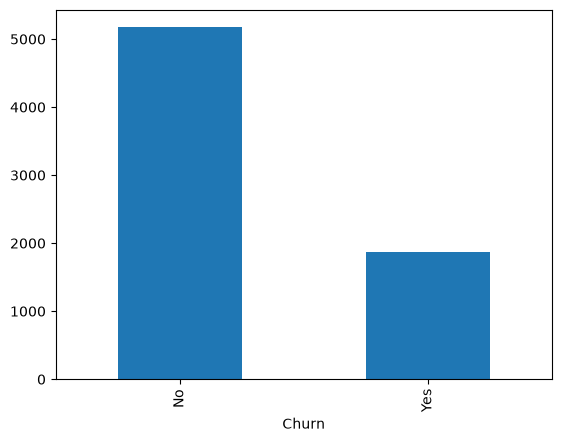

In [112]:
df_cleaned["Churn"].value_counts().plot(kind = 'bar')

<Axes: xlabel='Churn', ylabel='tenure'>

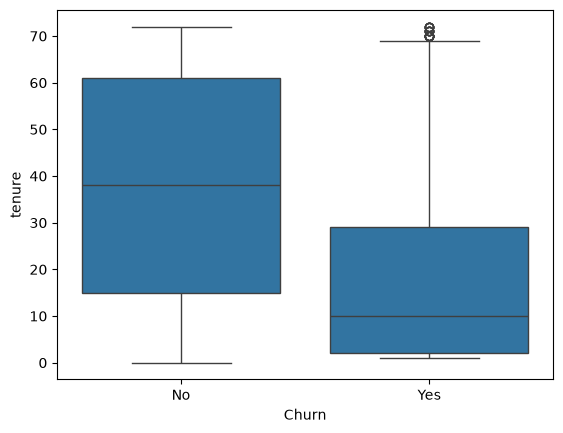

In [113]:
sns.boxplot(x = "Churn" , y = "tenure" , data= df_cleaned)

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

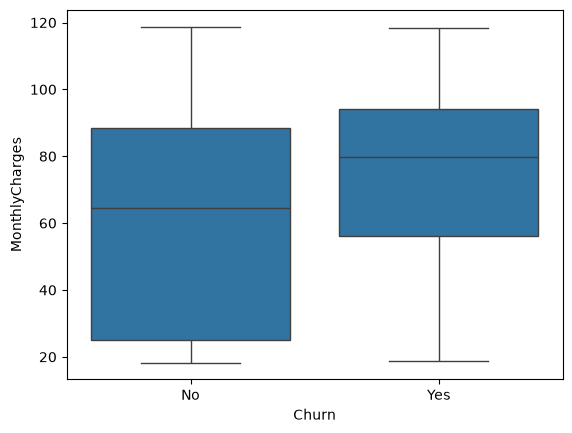

In [114]:
sns.boxplot(x = "Churn" , y = "MonthlyCharges" , data= df_cleaned)

In [115]:
df_cleaned["TotalCharges"] = pd.to_numeric(df_cleaned["TotalCharges"] , errors = "coerce")

In [116]:
# Keep categorical features as text until after the train/test split.

In [117]:
y = df_cleaned["Churn"].map({"Yes" : 1 , "No" : 0})
x = df_cleaned.drop('Churn', axis = 1)


In [118]:
# The encoder in cell 24 handles all categorical features after splitting.

In [119]:
y.value_counts(dropna=False)

Churn
0    5174
1    1869
Name: count, dtype: int64

In [120]:
x.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [121]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [122]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cols = ['tenure',	'MonthlyCharges',	'TotalCharges']

# Fit scaling after splitting and filling missing values below.


In [123]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [124]:
x_train , x_val , y_train , y_val = train_test_split(
    x_train , y_train , test_size=0.2 , random_state=42 , stratify = y_train
)

In [125]:
# Learn the replacement value from training data only.
training_mean = x_train["TotalCharges"].mean()
x_train["TotalCharges"] = x_train["TotalCharges"].fillna(training_mean)
x_test["TotalCharges"] = x_test["TotalCharges"].fillna(training_mean)
x_val["TotalCharges"] = x_val["TotalCharges"].fillna(training_mean)

# Learn scaling statistics from training customers only.
x_train[cols] = scaler.fit_transform(x_train[cols])
x_val[cols] = scaler.transform(x_val[cols])
x_test[cols] = scaler.transform(x_test[cols])


In [126]:
from sklearn.preprocessing import OneHotEncoder

# Discover categorical columns from training data only.
categorical_cols = x_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int)

# Fit once on training data; reuse the learned categories for test data.
train_categories = encoder.fit_transform(x_train[categorical_cols])
test_categories = encoder.transform(x_test[categorical_cols])
encoded_columns = encoder.get_feature_names_out(categorical_cols)
val_categories = encoder.transform(x_val[categorical_cols])


# Preserve row indices so the encoded values stay with the correct customers.
x_train = pd.concat([
    x_train.drop(columns=categorical_cols),
    pd.DataFrame(train_categories, columns=encoded_columns, index=x_train.index)
], axis=1)
x_test = pd.concat([
    x_test.drop(columns=categorical_cols),
    pd.DataFrame(test_categories, columns=encoded_columns, index=x_test.index)
], axis=1)
x_val = pd.concat([
    x_val.drop(columns=categorical_cols),
    pd.DataFrame(val_categories, columns=encoded_columns, index=x_val.index)
], axis=1)

x_train.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
6592,0,-0.255392,-0.174760,-0.342400,0,1,1,0,1,0,...,0,0,1,0,1,0,0,1,0,0
464,1,1.610432,1.710993,2.686977,0,1,0,1,1,0,...,1,0,0,1,0,1,1,0,0,0
5420,0,1.529309,1.652688,2.616446,0,1,0,1,1,0,...,1,0,0,1,1,0,0,1,0,0
629,1,0.677520,0.844746,0.992799,0,1,0,1,1,0,...,1,1,0,0,1,0,0,1,0,0
431,0,1.610432,0.016814,1.096971,1,0,0,1,0,1,...,1,0,0,1,0,1,0,1,0,0


In [127]:
x_train

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
6592,0,-0.255392,-0.174760,-0.342400,0,1,1,0,1,0,...,0,0,1,0,1,0,0,1,0,0
464,1,1.610432,1.710993,2.686977,0,1,0,1,1,0,...,1,0,0,1,0,1,1,0,0,0
5420,0,1.529309,1.652688,2.616446,0,1,0,1,1,0,...,1,0,0,1,1,0,0,1,0,0
629,1,0.677520,0.844746,0.992799,0,1,0,1,1,0,...,1,1,0,0,1,0,0,1,0,0
431,0,1.610432,0.016814,1.096971,1,0,0,1,0,1,...,1,0,0,1,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5537,1,1.569870,1.677676,2.516446,0,1,0,1,1,0,...,1,0,0,1,0,1,1,0,0,0
1729,0,1.285941,0.824756,1.495828,0,1,0,1,1,0,...,0,0,1,0,1,0,1,0,0,0
4930,0,-1.269426,-0.671186,-0.984669,1,0,1,0,1,0,...,0,1,0,0,0,1,0,1,0,0
2554,0,-0.579883,-0.489608,-0.612184,1,0,1,0,1,0,...,0,1,0,0,0,1,0,0,0,1


In [128]:
x_train.shape[1]

45

In [129]:
import torch 
import torch.nn as nn 

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [130]:
x_train_tensor = torch.tensor(x_train.to_numpy(dtype = np.float32))
y_train_tensor = torch.tensor(
    y_train.to_numpy(dtype = np.float32)
).reshape(-1 , 1)

x_val_tensor = torch.tensor(x_val.to_numpy(dtype=np.float32))
y_val_tensor = torch.tensor(
    y_val.to_numpy(dtype=np.float32)
).reshape(-1, 1)

x_test_tensor = torch.tensor(x_test.to_numpy(dtype=np.float32))
y_test_tensor = torch.tensor(
    y_test.to_numpy(dtype=np.float32)
).reshape(-1, 1)

In [ ]:
class MyANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(45 , 32)
        self.layer2 = nn.Linear(32 , 8)
        self.output = nn.Linear(8 , 1)
        self.relu = nn.ReLU()

    def forward(self , x):
        x = self.layer1(x)
        x = self.relu(x)

        x = self.layer2(x)
        x = self.relu(x)

        x = self.output(x)

        return x 



In [137]:
model = MyANN()

In [138]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

In [139]:
from torch.utils.data import TensorDataset , DataLoader 

dataset_train = TensorDataset(x_train_tensor , y_train_tensor)

train_loader = DataLoader(
    dataset_train,
    batch_size = 4,
    shuffle=True
)

dataset_train = TensorDataset(x_val_tensor , y_val_tensor)

val_loader = DataLoader(
    dataset_train,
    batch_size = 4,
    shuffle=False
)

In [141]:
for epoch in range(10):

    model.train()
    train_loss = 0

    for x_batch , y_batch in train_loader:

        optimizer.zero_grad()
        logits = model(x_batch)
        loss = criterion(logits , y_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
    train_loss/=len(train_loader)

    model.eval()

    val_loss = 0

    with torch.no_grad():

        for x_val_batch , y_val_batch in val_loader:

            val_pred = model(x_val_batch)

            loss = criterion(val_pred , y_val_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        "Epoch:", epoch,
        "Train Loss:", train_loss,
        "Val Loss:", val_loss
    )

Epoch: 0 Train Loss: 0.4217653044738279 Val Loss: 0.41787483152134197
Epoch: 1 Train Loss: 0.41962771797957626 Val Loss: 0.4236184997444457
Epoch: 2 Train Loss: 0.41814079554131733 Val Loss: 0.419110885669365
Epoch: 3 Train Loss: 0.41591189982172866 Val Loss: 0.4197861411945617
Epoch: 4 Train Loss: 0.4141152880940431 Val Loss: 0.41404215151325185
Epoch: 5 Train Loss: 0.41135702768758853 Val Loss: 0.41576658469354005
Epoch: 6 Train Loss: 0.411001936255722 Val Loss: 0.41601327605915406
Epoch: 7 Train Loss: 0.40867322009344387 Val Loss: 0.4150697817986316
Epoch: 8 Train Loss: 0.40734804802125496 Val Loss: 0.4165492168766387
Epoch: 9 Train Loss: 0.4073757379387688 Val Loss: 0.41291470870587


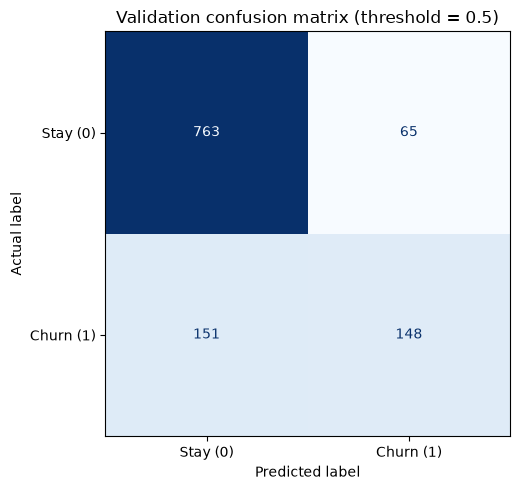

              precision    recall  f1-score   support

    Stay (0)      0.835     0.921     0.876       828
   Churn (1)      0.695     0.495     0.578       299

    accuracy                          0.808      1127
   macro avg      0.765     0.708     0.727      1127
weighted avg      0.798     0.808     0.797      1127



In [142]:
# Validation confusion matrix: 0 = stay, 1 = churn.
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

model.eval()
with torch.no_grad():
    # Use the same device as the trained model.
    val_logits = model(x_val_tensor.to(next(model.parameters()).device))
    val_probabilities = torch.sigmoid(val_logits)
    val_predictions = (val_probabilities >= 0.5).int().cpu().numpy().ravel()

val_actual = y_val_tensor.detach().cpu().numpy().ravel().astype(int)
val_cm = confusion_matrix(val_actual, val_predictions, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=["Stay (0)", "Churn (1)"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Validation confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.show()

print(classification_report(
    val_actual, val_predictions,
    labels=[0, 1], target_names=["Stay (0)", "Churn (1)"],
    digits=3, zero_division=0
))


In [143]:
torch.save(model.state_dict(), "model.pth")